# Machine Learning #10 - Object Detection in PyTorch 🎯

So far our networks answered one question: **"*what* is in the image?"**
Today we teach a network to answer a harder one: **"*what* is it, and *where* is it?"**

We will get there in two steps:

1. **From scratch** ⚪ — we build a small CNN that finds a white circle on a black background.
   It trains in seconds, yet it contains *every* core idea of real detectors.
2. **State of the art** 🚀 — we use **YOLO26**, a pretrained detector, on real photos and videos,
   fine-tune it on our own data and export it for deployment.

> **image → tensor → CNN → bounding box → IoU → pretrained detector → fine-tuning → export**

##### Remember to set **GPU** runtime in Colab!

# 📒 What is Object Localization?

* Object localization is the task of **classification with localization**.
* Given an image, we **classify** the object that appears in it **and find its location**,
  usually as a **bounding box** (a rectangle around the object).
* In object localization, **only a single object** can appear in the image.
    * 💡 If more than one object can appear, the task is called **Object Detection**.

| Task | Question it answers | Output | Objects per image |
|---|---|---|---|
| **Classification** | *What* is in the image? | class label | 1 |
| **Localization** | *What* is it and *where* is it? | class + **one** bounding box | exactly 1 |
| **Detection** | *What* and *where* are **all** the objects? | class + box **for every object** | 0 … many |

![model](https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/blob/main/images/dl_10_01.png?raw=true)

👉 **Part A** of today's lesson = **localization**, **Part B** = **detection**.

## 📌 Object localization can be treated as a regression problem

In classification the network outputs *probabilities of classes*.
In localization it outputs **numbers describing a rectangle** — that is a **regression** task.

### We can represent our output (a bounding box) as a tuple of size 4:
* `(x, y, width, height)`
    * `x, y`: the coordinates of the **top-left corner** of the bounding box
    * `width`: the width of the bounding box
    * `height`: the height of the bounding box

![model2](https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/blob/main/images/dl_10_02.png?raw=true)

## 📦 Bounding box formats

The **same rectangle** can be written down in several ways. Different libraries use different
formats, so it pays off to know all three:

| Format | The four numbers | Who uses it |
|---|---|---|
| `xywh` | top-left corner $(x, y)$ + width $w$ + height $h$ | **our synthetic dataset** (Part A) |
| `xyxy` | top-left corner $(x_1, y_1)$ + bottom-right corner $(x_2, y_2)$ | `torchvision`, YOLO results (`boxes.xyxy`) |
| `cxcywh` | centre $(c_x, c_y)$ + width $w$ + height $h$ | YOLO label files (`.txt`) |

Converting between them is simple arithmetic:

$$x_2 = x + w, \qquad y_2 = y + h, \qquad c_x = x + \tfrac{w}{2}, \qquad c_y = y + \tfrac{h}{2}$$

Two more things to remember:

* 🧭 **Image coordinates start in the top-left corner** and the **y-axis points down** ⬇️
  (the opposite of what you know from maths class).
* 📐 We usually **normalize** coordinates — divide them by the image width/height — so every
  number lies in the range $[0, 1]$, no matter how big the image is.

## 📏 How do we know a predicted box is good? Intersection over Union (IoU)

We compare the **predicted** box $P$ with the **ground-truth** (correct) box $G$ by measuring how
much they overlap:

$$\text{IoU}(P, G) = \frac{\text{area}(P \cap G)}{\text{area}(P \cup G)} = \frac{\text{overlap}}{\text{total area covered by both boxes}}$$

| IoU | Meaning |
|---|---|
| $0$ | boxes do not overlap at all ❌ |
| $< 0.5$ | poor localization 😕 |
| $\geq 0.5$ | commonly counted as a **correct detection** ✅ |
| $\geq 0.75$ | very precise 🎯 |
| $1$ | perfect match 💯 |

**Why not just measure the distance between coordinates?** 🤔
Because IoU is **scale-invariant**: a 5-pixel mistake is a disaster for a 10-pixel box, but
negligible for a 500-pixel box. IoU captures that, a plain distance does not.

**Worked example:** box A = `[10, 10, 60, 60]`, box B = `[30, 30, 80, 80]` (both `xyxy`, each 50 × 50 px)

* overlap = $30 \times 30 = 900$
* union = $2500 + 2500 - 900 = 4100$
* IoU = $900 / 4100 \approx 0.22$ — they overlap, but not nearly enough. We will check this in code in a moment.

### 📌 Network architecture in general

* The top-left corner of the box must lie **inside the image**, and so must `x + width` and `y + height`.
    * We scale the image width and height to be **1.0** (normalized coordinates).
    * So we make sure the CNN outputs are in the range `[0, 1]` — we put a **sigmoid** activation
      at the end:  $\sigma(z) = \dfrac{1}{1 + e^{-z}}$
        * 💡 It enforces that `(x, y)` will be inside the image, but **not necessarily** `x + width` and `y + height`.
        * 💡 This property has to be **learned** by the network during training.

![model3](https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/blob/main/images/dl_10_03.png?raw=true)

## 🔎 What about the loss?

The network outputs a few numbers in $[0, 1]$ and we want them to be **as close as possible** to the
correct numbers. Several losses can do that:

* **MSE** (mean squared error) — the classic regression loss.
* **Smooth L1** — the loss used by many real detectors (e.g. Faster R-CNN). **We will use this one.**
* Because the sigmoid outputs lie in $[0, 1]$, they can even be treated as "probabilities" and trained
  with **Binary Cross-Entropy**.
    * 📌 You can see [this](https://www.theaidream.com/post/loss-functions-in-neural-networks) or
      [this](https://github.com/christianversloot/machine-learning-articles/blob/main/about-loss-and-loss-functions.md) for more information.

## Imports and setup
Remember to set **GPU** runtime in Colab!

In [1]:
!pip install torchinfo

In [2]:
import copy
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib import font_manager
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

import torchvision
from torchvision.ops import box_convert, box_iou, nms
from torchvision.utils import draw_bounding_boxes
from torchvision.io import read_image

import torchinfo

from sklearn.model_selection import train_test_split

sns.set_theme(style="white")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch version:      ", torch.__version__)
print("torchvision version:", torchvision.__version__)
print("device:             ", device)

torch version:       2.14.1+cu130
torchvision version: 0.29.1+cu130
device:              cuda


### Bounding box tools in PyTorch 🧰

Before we build anything, let's try the two helpers we will use all the time:
`box_convert` (changes the format) and `box_iou` (computes IoU).

In [3]:
# One box written in the xywh format: top-left corner (10, 10), width 50, height 50
box_xywh = torch.tensor([[10.0, 10.0, 50.0, 50.0]])

print("xywh   :", box_xywh)
print("xyxy   :", box_convert(box_xywh, in_fmt="xywh", out_fmt="xyxy"))     # -> [10, 10, 60, 60]
print("cxcywh :", box_convert(box_xywh, in_fmt="xywh", out_fmt="cxcywh"))   # -> [35, 35, 50, 50]

xywh   : tensor([[10., 10., 50., 50.]])
xyxy   : tensor([[10., 10., 60., 60.]])
cxcywh : tensor([[35., 35., 50., 50.]])


In [4]:
# The worked example from above (both boxes in xyxy)
box_a = torch.tensor([[10.0, 10.0, 60.0, 60.0]])
box_b = torch.tensor([[30.0, 30.0, 80.0, 80.0]])

# box_iou compares EVERY box in the first tensor with EVERY box in the second one
# -> the result is a matrix of shape (len(box_a), len(box_b)); here (1, 1)
print("IoU:", box_iou(box_a, box_b))

IoU: tensor([[0.2195]])


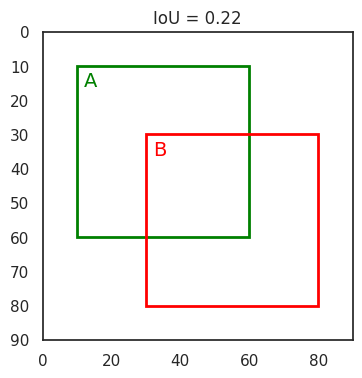

In [5]:
fig, ax = plt.subplots(figsize=(4, 4))
for box, color, name in [(box_a[0], "green", "A"), (box_b[0], "red", "B")]:
    x1, y1, x2, y2 = box.tolist()
    ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))
    ax.text(x1 + 2, y1 + 6, name, color=color, fontsize=14)
ax.set_xlim(0, 90)
ax.set_ylim(90, 0)   # ylim reversed: in images the y-axis points DOWN
ax.set_title(f"IoU = {box_iou(box_a, box_b).item():.2f}")
plt.show()

# Part A — Object localization from scratch ⚪

## ⚡ We will start with a purely synthetic use-case for educational purposes before we move to a more complex one 🙂

* 📌 Our task will be the **localization of white circles on a pure black background**.
    * We will assume that the white blobs are located in **square** bounding boxes for simplicity.
        * 🔎 How will the **output layer** look like for a task like this one?

<details>
<summary>💡 Click to reveal the answer</summary>

A square box needs only **3 numbers**: `x`, `y` (top-left corner) and `size` (width = height).
So the last layer has **3 neurons** followed by a **sigmoid**, which keeps every number in $[0, 1]$.
</details>

### Image tensors in PyTorch: channels first! 🧱

PyTorch stores a batch of images as a 4-D tensor in the order **(N, C, H, W)**:

| Symbol | Meaning | Our value |
|---|---|---|
| **N** | number of images | 512 |
| **C** | number of channels (1 = grayscale, 3 = RGB) | 1 |
| **H** | image height in pixels | 128 |
| **W** | image width in pixels | 128 |

> 💡 Image libraries (matplotlib, PIL, OpenCV) usually use **(H, W, C)** — channels **last**.
> PyTorch wants channels **first**. Keep this in mind whenever you move images between the two worlds.

In [6]:
IMG_SIZE = 128

def make_dataset(n_images=512, img_size=IMG_SIZE, square=True, noise=0.0, seed=SEED):
    rng = np.random.default_rng(seed)
    X = np.zeros((n_images, 1, img_size, img_size), dtype=np.float32)
    labels = np.zeros((n_images, 3 if square else 4), dtype=np.float32)

    rows, cols = np.ogrid[:img_size, :img_size]

    for i in range(n_images):
        cx = rng.integers(8, img_size - 8)
        cy = rng.integers(8, img_size - 8)

        max_r = min(cx, cy, img_size - cx, img_size - cy)

        rx = rng.integers(4, max_r + 1)
        ry = rx if square else rng.integers(4, max_r + 1)

        inside = ((cols - cx) / rx) ** 2 + ((rows - cy) / ry) ** 2 < 1
        X[i, 0][inside] = 1.0

        if square:
            labels[i] = [(cx - rx) / img_size, (cy - ry) / img_size, 2 * rx / img_size]
        else:
            labels[i] = [(cx - rx) / img_size, (cy - ry) / img_size,
                         2 * rx / img_size, 2 * ry / img_size]
    if noise > 0:
        X = np.clip(X + rng.normal(0, noise, X.shape).astype(np.float32), 0.0, 1.0)

    return X, labels

In [7]:
X, labels = make_dataset(n_images=512)

In [8]:
X.shape        # (N, C, H, W) = (number of images, channels, height, width)

(512, 1, 128, 128)

In [9]:
labels.shape   # (number of images, 3) -> [x, y, size]

(512, 3)

In [10]:
labels[0]      # the normalized bounding box of the first image

array([0.03125  , 0.6328125, 0.203125 ], dtype=float32)

## We can check an example of the input image

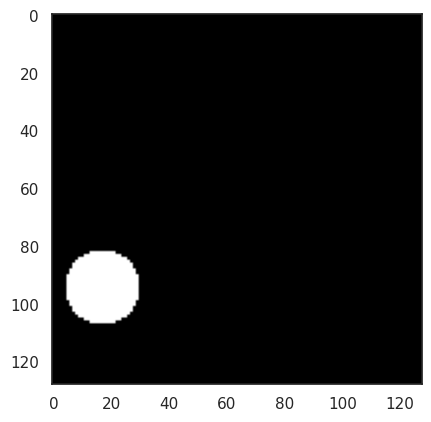

In [11]:
plt.imshow(X[0, 0], cmap="gray")
plt.show()

In [12]:
def draw_box(ax, box, color="g", img_size=IMG_SIZE, linewidth=2):
    box = np.asarray(box, dtype=float)
    x, y = box[0], box[1]
    w = box[2]
    h = box[3] if len(box) == 4 else box[2]
    ax.add_patch(Rectangle(
        xy=(x * img_size, y * img_size),
        width=w * img_size, height=h * img_size,
        linewidth=linewidth, edgecolor=color, facecolor="none",
    ))

def plot_pred(img, true_box=None, pred_box=None, ax=None, title=None):
    if ax is None:
        _, ax = plt.subplots(1)
    ax.imshow(np.asarray(img).reshape(IMG_SIZE, IMG_SIZE), cmap="gray")
    if true_box is not None:
        draw_box(ax, true_box, color="g")
    if pred_box is not None:
        draw_box(ax, pred_box, color="r")
    if title:
        ax.set_title(title, fontsize=8)
    ax.axis("off")

## And also with the ground-truth bounding box plotted

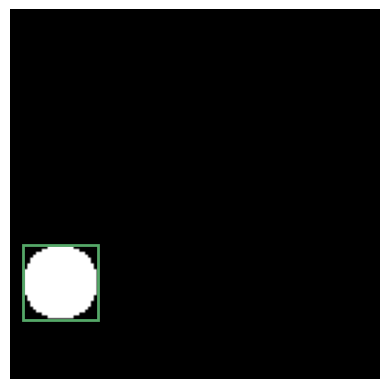

In [13]:
plot_pred(X[0], true_box=labels[0])
plt.show()

## More examples of our input data with bounding boxes incoming 🙂
* 💡 We can see that the circles vary in **position** and **size**.

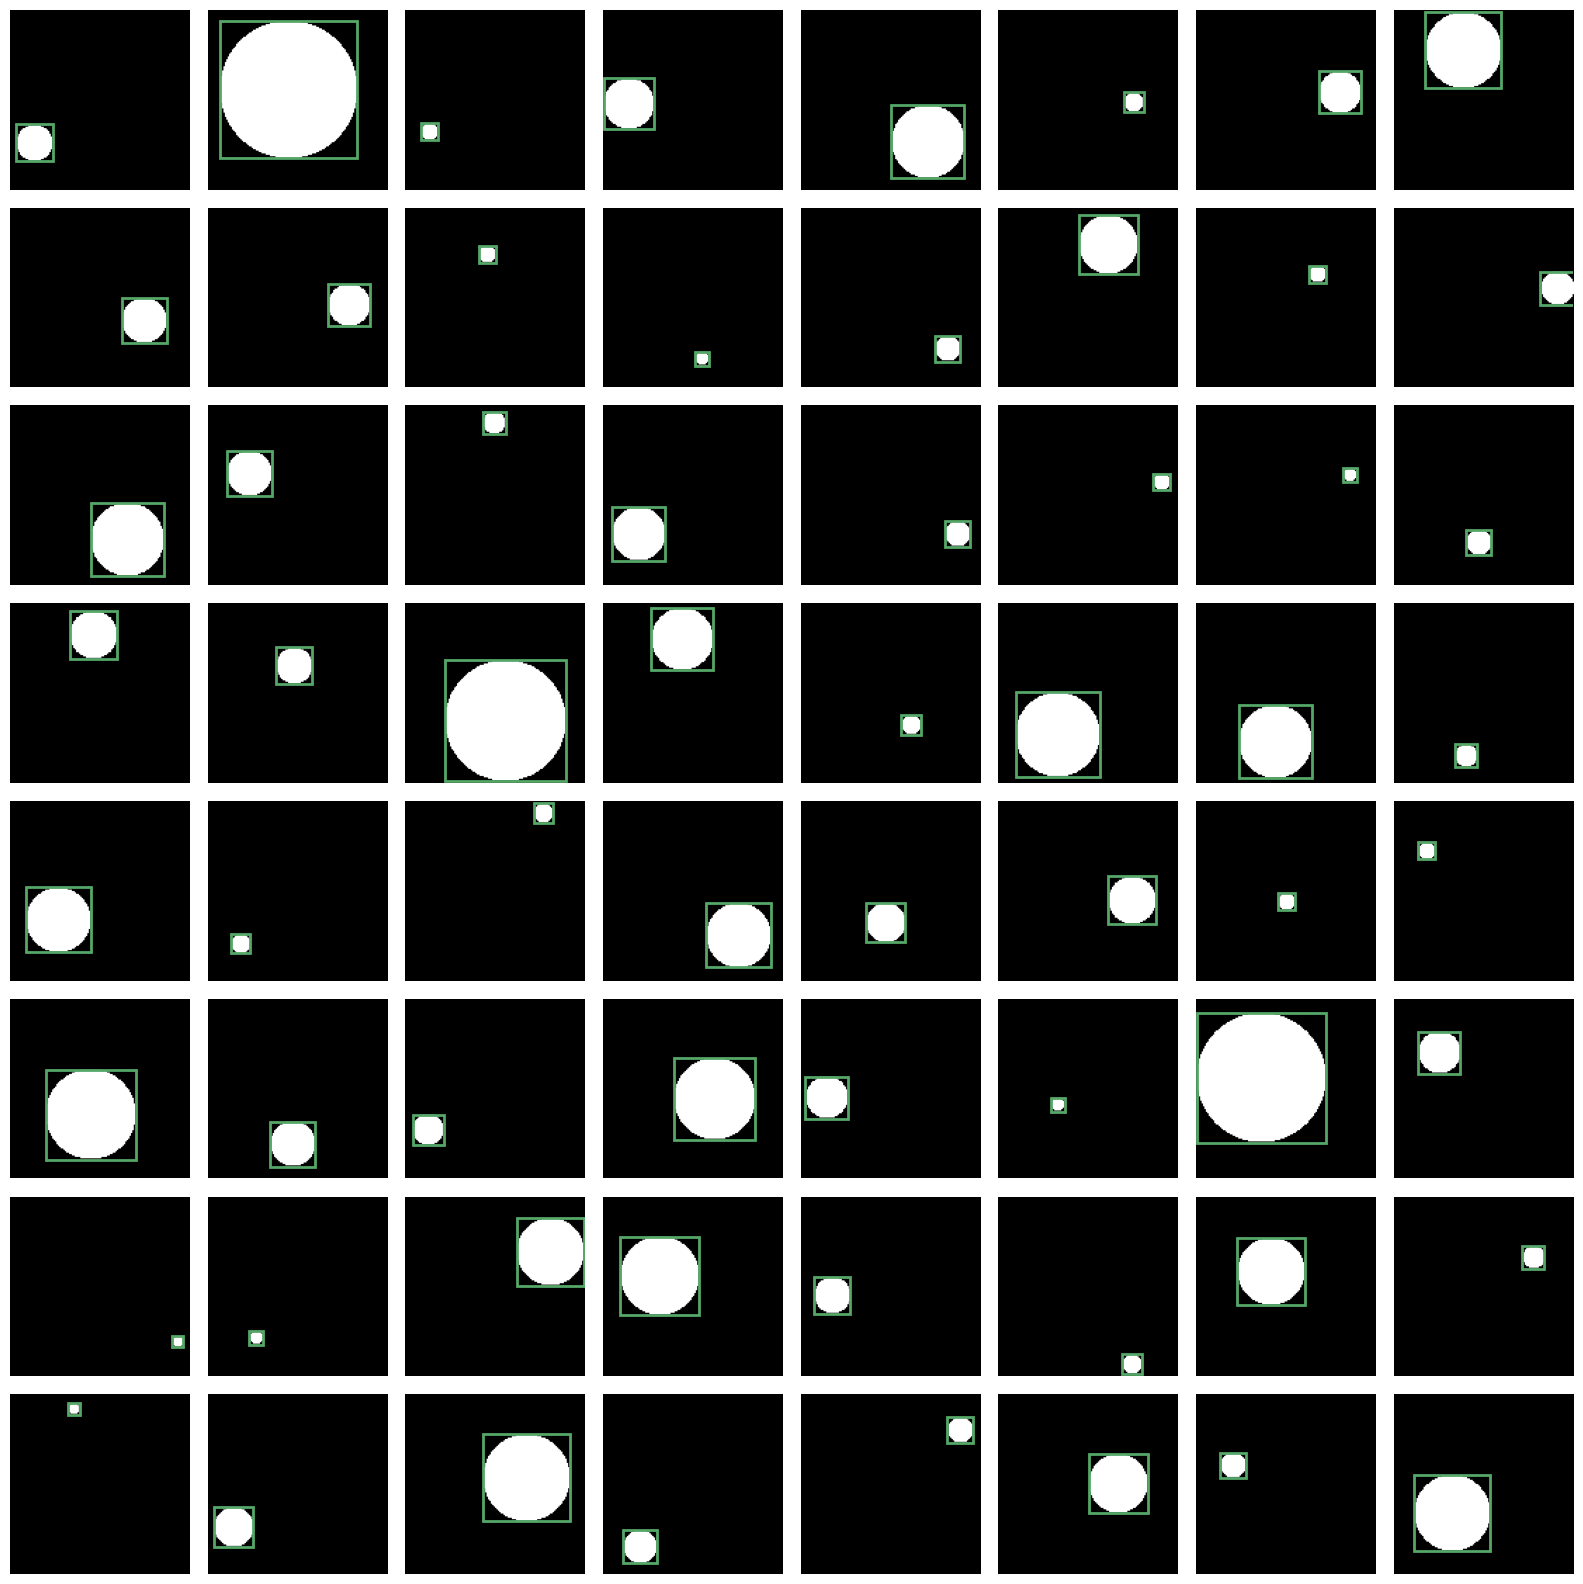

In [14]:
fig, ax = plt.subplots(8, 8, figsize=(16, 16))
for i in range(8):
    for j in range(8):
        plot_pred(X[i * 8 + j], true_box=labels[i * 8 + j], ax=ax[i, j])
plt.tight_layout()
plt.show()

## Train / validation / test split ✂️

Same idea as in every lesson so far:

* **train** — the network learns from it,
* **validation** — we watch it during training and pick the best model,
* **test** — touched only once, at the very end, for an honest final score.

In [15]:
X_temp, X_test, y_temp, y_test = train_test_split(X, labels, test_size=0.2, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2, random_state=SEED)

X_train.shape, X_val.shape, X_test.shape

((327, 1, 128, 128), (82, 1, 128, 128), (103, 1, 128, 128))

### From NumPy to tensors — and to mini-batches 📦

In [16]:
X_train_tensor, y_train_tensor = torch.tensor(X_train), torch.tensor(y_train)
X_val_tensor,   y_val_tensor   = torch.tensor(X_val),   torch.tensor(y_val)
X_test_tensor,  y_test_tensor  = torch.tensor(X_test),  torch.tensor(y_test)

batch_size = 32

train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_tensor,   y_val_tensor),   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test_tensor,  y_test_tensor),  batch_size=batch_size, shuffle=False)

print("Batches per epoch:", len(train_loader))

Batches per epoch: 11


In [17]:
xb, yb = next(iter(train_loader))
print("images:", xb.shape)
print("labels:", yb.shape)

images: torch.Size([32, 1, 128, 128])
labels: torch.Size([32, 3])


## 🚀 Let's define our first object localization model!

A typical CNN has two parts:

1. **Feature extractor** — convolution + pooling layers that find edges, curves and blobs.
2. **Head** — fully connected layers that turn those features into the **3 box numbers**.

| Layer | What it does | Output shape (C, H, W) |
|---|---|---|
| input | grayscale image | (1, 128, 128) |
| `Conv2d(1 → 64)` + `ReLU` | 64 filters of size 3×3 | (64, 128, 128) |
| `MaxPool2d(2)` | halves height and width | (64, 64, 64) |
| `Conv2d(64 → 64)` + `ReLU` + `MaxPool2d(2)` | | (64, 32, 32) |
| `Conv2d(64 → 16)` + `ReLU` + `MaxPool2d(2)` | fewer filters, more abstract features | (16, 16, 16) |
| `Flatten` | 3-D feature map → 1-D vector | $16 \cdot 16 \cdot 16 = 4096$ |
| `Linear(4096 → 64)` + `ReLU` + `Dropout(0.25)` | | 64 |
| `Linear(64 → 32)` + `ReLU` + `Dropout(0.25)` | | 32 |
| `Linear(32 → 3)` + **`Sigmoid`** | the box, every value in $[0, 1]$ | 3 |

* `padding=1` keeps the height and width unchanged after a 3×3 convolution.
* **Dropout** randomly switches off 25 % of the neurons in every training step — a protection against overfitting.

We wrap the model in a small function `build_model()`, so we can easily create **fresh** copies later in the activities.

In [18]:
def build_model(n_outputs=3):
    return nn.Sequential(
        nn.Conv2d(1, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Flatten(),
        nn.Linear(16 * 16 * 16, 64),
        nn.ReLU(),
        nn.Dropout(0.25),

        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Dropout(0.25),

        nn.Linear(32, n_outputs),
        nn.Sigmoid(),
    )

model = build_model(n_outputs=3).to(device)
print(model)

Sequential(
  (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=4096, out_features=64, bias=True)
  (11): ReLU()
  (12): Dropout(p=0.25, inplace=False)
  (13): Linear(in_features=64, out_features=32, bias=True)
  (14): ReLU()
  (15): Dropout(p=0.25, inplace=False)
  (16): Linear(in_features=32, out_features=3, bias=True)
  (17): Sigmoid()
)


In [19]:
torchinfo.summary(model, input_size=(1, 1, IMG_SIZE, IMG_SIZE))

Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 3]                    --
├─Conv2d: 1-1                            [1, 64, 128, 128]         640
├─ReLU: 1-2                              [1, 64, 128, 128]         --
├─MaxPool2d: 1-3                         [1, 64, 64, 64]           --
├─Conv2d: 1-4                            [1, 64, 64, 64]           36,928
├─ReLU: 1-5                              [1, 64, 64, 64]           --
├─MaxPool2d: 1-6                         [1, 64, 32, 32]           --
├─Conv2d: 1-7                            [1, 16, 32, 32]           9,232
├─ReLU: 1-8                              [1, 16, 32, 32]           --
├─MaxPool2d: 1-9                         [1, 16, 16, 16]           --
├─Flatten: 1-10                          [1, 4096]                 --
├─Linear: 1-11                           [1, 64]                   262,208
├─ReLU: 1-12                             [1, 64]                   --
├─

## ⚖️ Loss function and optimizer

**Loss — Smooth L1.** Let $d$ be the difference between a predicted and a true coordinate:

$$
\text{SmoothL1}(d) =
\begin{cases}
\dfrac{0.5\, d^2}{\beta} & \text{if } |d| < \beta \quad \text{(small error → behaves like MSE)} \\[2mm]
|d| - 0.5\,\beta & \text{otherwise} \quad \text{(big error → behaves like L1)}
\end{cases}
$$

* Small errors are punished **gently and smoothly** (nice gradients near the optimum).
* Big errors are punished **linearly**, so one terrible box does not dominate the whole batch.
* ⚠️ Our coordinates live in $[0, 1]$, so we set $\beta = 0.05$ (≈ 6 pixels).
  With the default $\beta = 1$ every error would count as "small" and the loss would be just MSE in disguise.

**Optimizer — Adam** with learning rate `1e-3`, our reliable default.

**Metric — mean IoU.** The loss tells the *network* how to improve; the IoU tells *us* how good the boxes are.
The two helpers below convert our `xywh` boxes to `xyxy` and compute the IoU of every predicted box
with its own ground-truth box.

In [20]:
criterion = nn.SmoothL1Loss(beta=0.05)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [21]:
def to_xyxy(boxes):
    """[x, y, size] or [x, y, w, h] (tensor of shape (N, 3) / (N, 4))  ->  [x1, y1, x2, y2]."""
    if boxes.shape[1] == 3:                                   # square box: height = width
        boxes = torch.cat([boxes, boxes[:, 2:3]], dim=1)
    return box_convert(boxes, in_fmt="xywh", out_fmt="xyxy")

def iou_per_box(pred, target):
    """IoU of every predicted box with ITS OWN ground-truth box -> tensor of shape (N,)."""
    # box_iou returns an (N, N) matrix (every box vs every box);
    # we only need the diagonal = prediction i vs ground truth i
    return box_iou(to_xyxy(pred), to_xyxy(target)).diagonal()

def mean_iou(pred, target):
    return iou_per_box(pred, target).mean().item()

## ⭐ The training loop
### Saving the best model 💾

Training does not always improve the model until the very last epoch — sometimes the validation
loss goes up again (overfitting). So we remember the weights from the epoch with the **lowest validation loss**.

* `model.state_dict()` returns a **dictionary with all the weights** of the network.
* `copy.deepcopy(...)` makes a real copy — otherwise we would only store a reference that keeps changing.
* At the end we save it to disk with `torch.save(...)` and load it back with `model.load_state_dict(...)`.

In [22]:
n_epochs = 100
history = {"train_loss": [], "val_loss": [], "val_iou": []}

best_val_loss = float("inf")
best_state = None

start = time.time()
for epoch in range(n_epochs):
    model.train()
    running_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        preds = model(xb)
        loss = criterion(preds, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * xb.size(0)
    train_loss = running_loss / len(train_loader.dataset)

    model.eval()
    running_loss, val_preds = 0.0, []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb)
            running_loss += criterion(preds, yb).item() * xb.size(0)
            val_preds.append(preds.cpu())
    val_loss = running_loss / len(val_loader.dataset)
    val_iou = mean_iou(torch.cat(val_preds), y_val_tensor)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)

    # ---------- REMEMBER THE BEST MODEL ----------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())

    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch + 1:3d} | train loss {train_loss:.4f} | "
              f"val loss {val_loss:.4f} | val IoU {val_iou:.3f}")

print(f"Training took {time.time() - start:.1f} s")

epoch  10 | train loss 0.0508 | val loss 0.0201 | val IoU 0.437
epoch  20 | train loss 0.0436 | val loss 0.0160 | val IoU 0.501
epoch  30 | train loss 0.0390 | val loss 0.0154 | val IoU 0.502
epoch  40 | train loss 0.0400 | val loss 0.0173 | val IoU 0.502
epoch  50 | train loss 0.0313 | val loss 0.0137 | val IoU 0.535
epoch  60 | train loss 0.0310 | val loss 0.0119 | val IoU 0.572
epoch  70 | train loss 0.0327 | val loss 0.0133 | val IoU 0.573
epoch  80 | train loss 0.0298 | val loss 0.0148 | val IoU 0.512
epoch  90 | train loss 0.0299 | val loss 0.0141 | val IoU 0.557
epoch 100 | train loss 0.0272 | val loss 0.0121 | val IoU 0.582
Training took 6.9 s


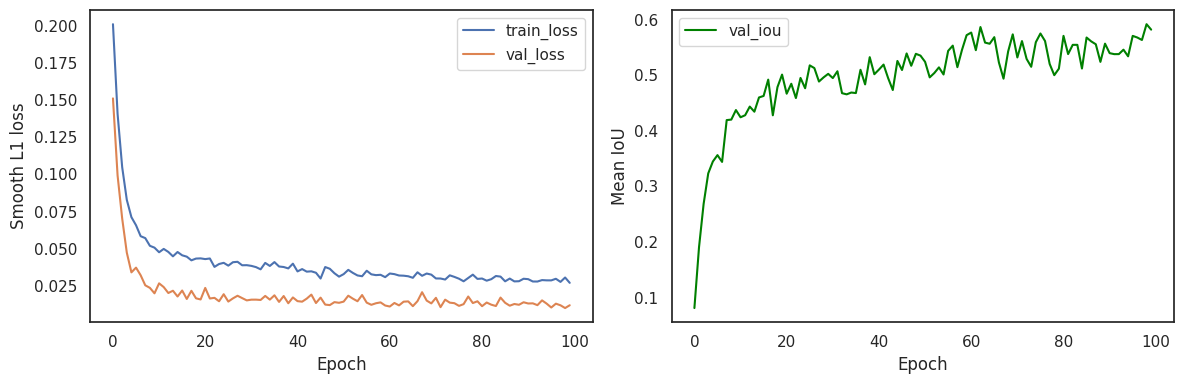

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history["train_loss"], label="train_loss")
ax[0].plot(history["val_loss"], label="val_loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Smooth L1 loss")
ax[0].legend()

ax[1].plot(history["val_iou"], label="val_iou", color="green")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Mean IoU")
ax[1].legend()

plt.tight_layout()
plt.show()

> 💡 Why is the **validation** loss lower than the **training** loss at the beginning?
> Dropout is **on** during training (the network is handicapped) and **off** during validation.

In [24]:
# Save the best weights to a file and load them back into the model
torch.save(best_state, "best_localizer.pt")
model.load_state_dict(torch.load("best_localizer.pt"))
print(f"Loaded the best model (val loss = {best_val_loss:.4f})")

Loaded the best model (val loss = 0.0102)


## 📊 Evaluation

Now the honest check on the **test** set. We also evaluate the **training** set — if the training
IoU were much higher than the test IoU, the model would be **overfitting**.

The helper `predict()` runs the model in batches, in evaluation mode and without gradients.

In [25]:
def predict(model, X_np, batch_size=128):
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X_np), batch_size):
            xb = torch.tensor(X_np[i:i + batch_size]).to(device)
            preds.append(model(xb).cpu())
    return torch.cat(preds)

def evaluate_iou(model, X_np, y_np):
    return mean_iou(predict(model, X_np), torch.tensor(y_np))

In [26]:
y_pred = predict(model, X_test)

test_ious = iou_per_box(y_pred, y_test_tensor).numpy()

print(f"Test  loss:     {criterion(y_pred, y_test_tensor).item():.4f}")
print(f"Test  mean IoU: {test_ious.mean():.3f}")
print(f"Train mean IoU: {evaluate_iou(model, X_train, y_train):.3f}")
print(f"Boxes with IoU >= 0.5 (counted as correct): {(test_ious >= 0.5).mean() * 100:.1f} %")

Test  loss:     0.0071
Test  mean IoU: 0.588
Train mean IoU: 0.643
Boxes with IoU >= 0.5 (counted as correct): 71.8 %


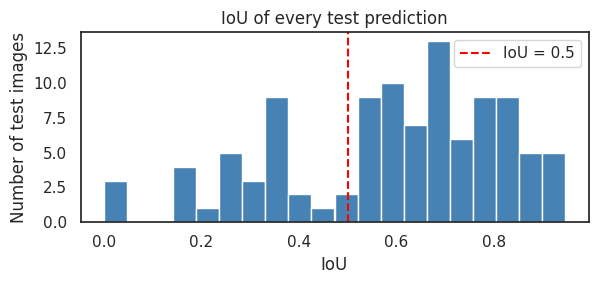

In [27]:
plt.figure(figsize=(6, 3))
plt.hist(test_ious, bins=20, color="steelblue", edgecolor="white")
plt.axvline(0.5, color="red", linestyle="--", label="IoU = 0.5")
plt.xlabel("IoU"); plt.ylabel("Number of test images")
plt.title("IoU of every test prediction")
plt.legend(); plt.tight_layout(); plt.show()

# ⚡ Now we can take a look at our predictions
* 🟩 **green** = ground truth, 🟥 **red** = prediction, the number above = IoU
* Some predictions are spot-on, some are noticeably off.
* 💪 Remember your **test IoU** — in the activities you will try to beat it!

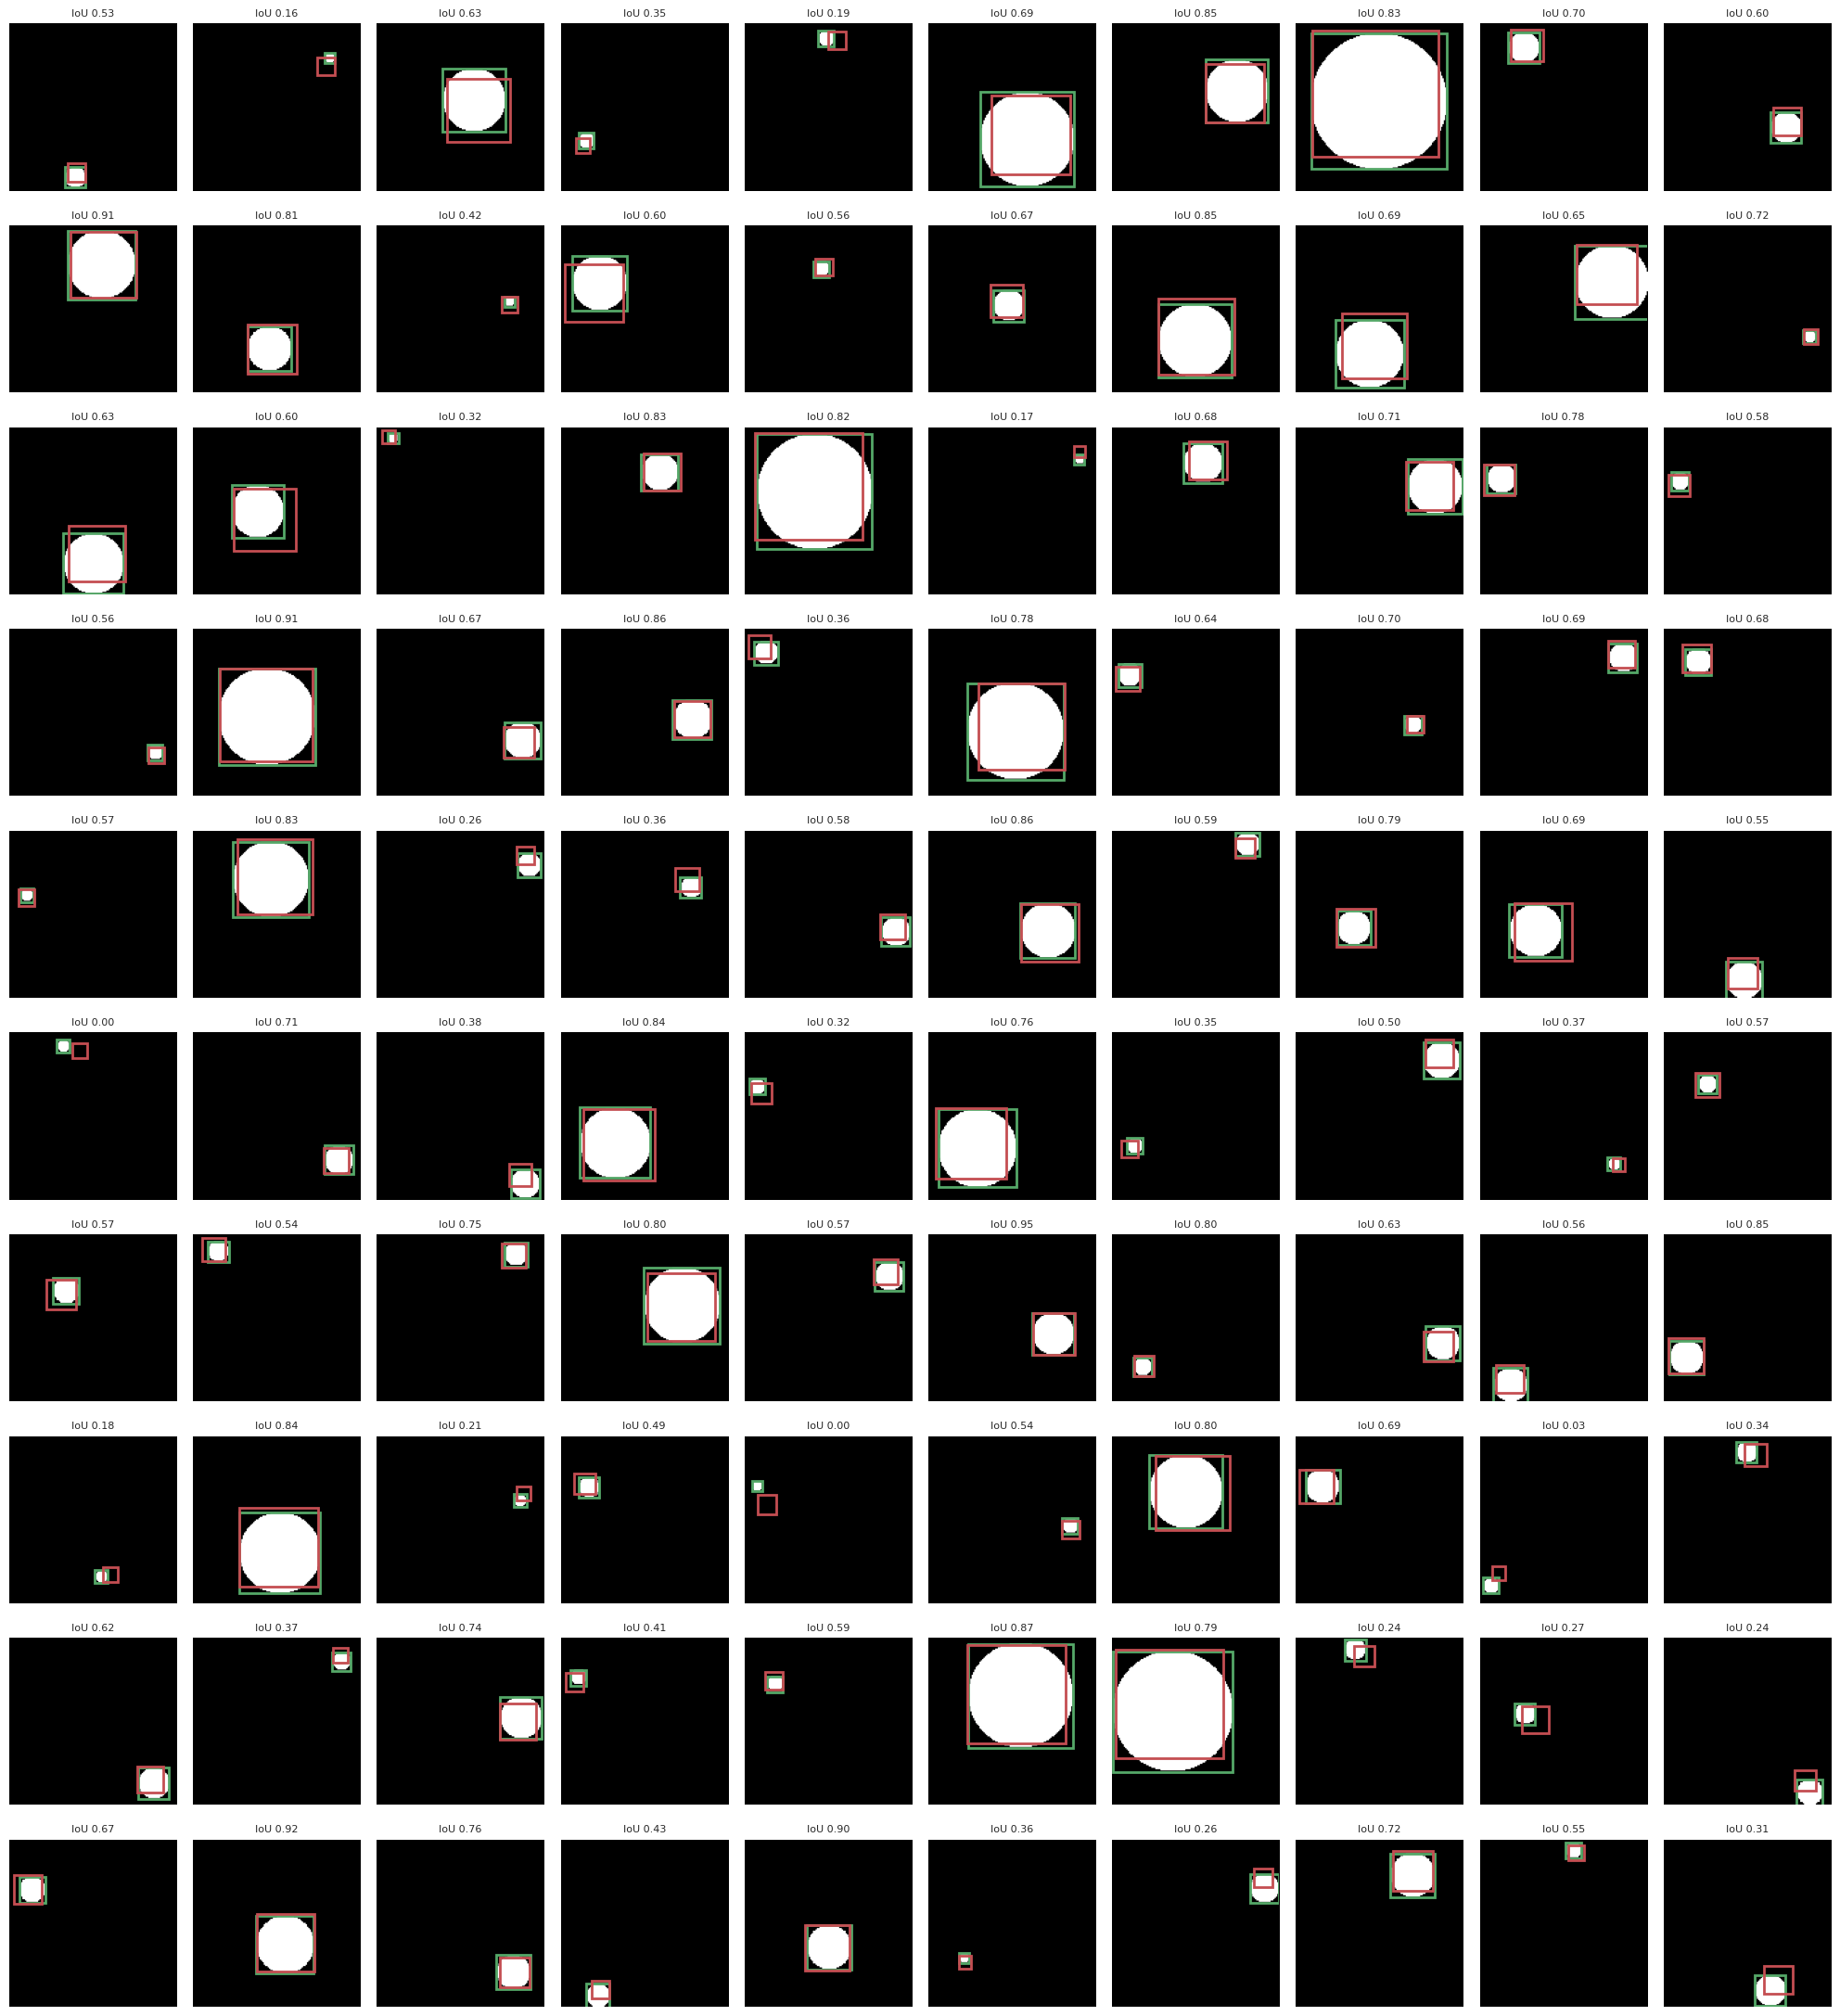

In [28]:
nrows = 10
fig, ax = plt.subplots(nrows, nrows, figsize=(20, 22))
for i in range(nrows):
    for j in range(nrows):
        k = i * nrows + j
        plot_pred(X_test[k], true_box=y_test[k], pred_box=y_pred[k].numpy(),
                  ax=ax[i, j], title=f"IoU {test_ious[k]:.2f}")
plt.tight_layout()
plt.show()

# Part B — Pretrained detectors 🚀

## Now we know the basics, so we can focus on more interesting stuff
* Usually you **don't want to train your own model** for the task, but you leverage the **transfer learning** approach.
* 💡 Object localization / detection is no exception.
* Object detection is a very common task and there is already a wide variety of pretrained models focused on it.

## 📌 The current state-of-the-art family: [Ultralytics YOLO](https://github.com/ultralytics/ultralytics) — **YOLO26**
* **YOLO** = *You Only Look Once*: the whole image goes through the network **once** and all boxes come out together → very fast, suitable for real-time video.
* Useful for a wide range of tasks: **object detection** and tracking, **instance segmentation**, **image classification**, **pose estimation** and **oriented boxes**.
* Can be used from the **Command Line Interface** (CLI) or from **Python**.
* 🔥 It is built on **PyTorch** — a `.pt` file with YOLO weights is a regular PyTorch checkpoint.
* YOLO26 is **end-to-end**: it outputs one box per object directly, without the extra post-processing step called NMS (more on that below ✂️).
* Pretrained models come in **5 sizes** — the same trade-off as always: bigger = more accurate, but slower.

| Model | Size | Typical use |
|---|---|---|
| `yolo26n` | nano | phones, edge devices, real-time on CPU ⚡ |
| `yolo26s` | small | good balance for a laptop |
| `yolo26m` | medium | servers with a GPU |
| `yolo26l` | large | when accuracy matters more than speed |
| `yolo26x` | extra large | maximum accuracy 🎯, slowest |

### 💡 PyTorch has its own pretrained detectors too
* `torchvision.models.detection` contains classic detectors such as **Faster R-CNN**, **RetinaNet**, **SSD** and **FCOS**.
* They are a bit more work to use than YOLO, but they show nicely what happens "under the hood".
  You will try one of them in **Activity 9**.

# ⚡ We will start with a simple zero-shot object detection
* 🔎 What is meant by a *zero-shot* approach?

<details>
<summary>💡 Click to reveal the answer</summary>

We use the pretrained model **as it is** — no training at all on our data ("zero" training examples, "zero shots").
The model was trained on the **COCO** dataset with **80 everyday classes** (person, car, bus, dog, …), and we simply ask it what it sees.

⚠️ Strictly speaking, in research *zero-shot* means recognising classes the model has **never seen** during training
(e.g. models that accept a text prompt like *"red umbrella"*). Here we only detect classes the model already knows,
so a more precise name would be **off-the-shelf inference**. In practice you will hear both.
</details>

In [29]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 15.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [30]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [31]:
!wget https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/blob/main/misc/bus.jpg?raw=true -O bus.jpg
!wget https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/releases/download/v0.0.01/video_cut.mkv -O video_cut.mkv

--2026-11-15 10:06:04--  https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/blob/main/misc/bus.jpg?raw=true
Resolving github.com (github.com)... 140.82.121.4
Connecting to github.com (github.com)|140.82.121.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/raw/refs/heads/main/misc/bus.jpg [following]
--2026-11-15 10:06:04--  https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/raw/refs/heads/main/misc/bus.jpg
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/rasvob/VSB-FEI-Deep-Learning-Exercises/refs/heads/main/misc/bus.jpg [following]
--2026-11-15 10:06:04--  https://raw.githubusercontent.com/rasvob/VSB-FEI-Deep-Learning-Exercises/refs/heads/main/misc/bus.jpg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.108.133, 185.199.111.133, ...
Connecting to ra

## Load the model
* The weights file `yolo26n.pt` is **downloaded automatically** the first time you use it.
* We call the variable `yolo`, so we do not overwrite our own `model` from Part A.

In [32]:
# Pretrained YOLO26 nano model, trained on the COCO dataset (80 classes)
yolo = YOLO("yolo26n.pt", verbose=True)

### 🔍 Under the hood: YOLO is just an `nn.Module`

The Ultralytics library wraps everything in a friendly API, but inside there is a regular PyTorch network —
exactly the same kind of object as the CNN we built in Part A.

In [33]:
net = yolo.model
n_params = sum(p.numel() for p in net.parameters())

print("Type:                ", type(net).__name__)
print("Is it an nn.Module?  ", isinstance(net, nn.Module))
print(f"Number of parameters: {n_params:,}")
print(f"Our Part A CNN:       {sum(p.numel() for p in model.parameters()):,}")

Type:                 DetectionModel
Is it an nn.Module?   True
Number of parameters: 2,572,280
Our Part A CNN:       311,187


## 🚀 The model is ready to use
* The model call has several useful parameters:

| Parameter | What it does |
|---|---|
| `save` | saves the annotated images or videos to a file |
| `save_txt` | saves the bounding boxes and class labels to a text file — 💡 format: `[class] [x_center] [y_center] [width] [height] [confidence]` (the `cxcywh` format!) |
| `save_conf` | includes the confidence scores in the saved text files (you can filter out low-confidence detections later) |
| `imgsz` | image size for inference — 💡 a single integer for square resizing or a `(height, width)` tuple |
| `project` | folder name for saving the output |
| `conf` | minimum confidence of a detection (default `0.25`) |
| `classes` | detect only the listed class IDs |

In [34]:
# Run object detection on bus.jpg
#   save_txt=True  -> boxes saved to a text file (YOLO format: class cx cy w h conf)
#   save_conf=True -> include the confidence score in that file
#   save=True      -> save the image with the boxes drawn on it
#   imgsz=1088     -> the image is resized to 1088 px for inference (bigger = more precise, but slower)
#   project="yolo" -> outputs go to the folder "yolo/"
res = yolo("bus.jpg", save_txt=True, save_conf=True, save=True, imgsz=1088, project="yolo")


image 1/1 /content/bus.jpg: 1088x832 4 persons, 1 bus, 14.2ms
Speed: 97.6ms preprocess, 14.2ms inference, 7.7ms postprocess per image at shape (1, 3, 1088, 832)
Results saved to /content/runs/detect/yolo/predict
1 label saved to /content/runs/detect/yolo/predict/labels


In [35]:
res

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair',

## If you want to work with the detected bounding boxes, you can use the following code
* `result.boxes.xyxy` — box coordinates in **pixels of the original image** (`xyxy` format)
* `result.boxes.cls` — class ID of every box
* `result.boxes.conf` — confidence of every box
* All of them are **PyTorch tensors** (possibly on the GPU) → `.cpu().numpy()` turns them into NumPy arrays.

In [36]:
for i, result in enumerate(res):
    curr = result.boxes.xyxy.cpu().numpy()

    if curr.shape[0] > 0:
        print(f"Image {i}")
        print(f"Found {curr.shape[0]} boxes")
        print(f"Classes:  {result.boxes.cls.cpu().numpy()}")
        for j, box in enumerate(curr):
            print(f"Box {j}: {box}")

Image 0
Found 5 boxes
Classes:  [          0           0           0           5           0]
Box 0: [     47.107      399.43      247.44      905.09]
Box 1: [     224.73      403.65      348.47      858.33]
Box 2: [     667.66      427.92         810      879.45]
Box 3: [     43.826       226.5       797.9      694.49]
Box 4: [          0      550.62      74.235      874.49]


In [37]:
def results_to_df(result):
    boxes = result.boxes
    df = pd.DataFrame(boxes.xyxy.cpu().numpy(), columns=["x1", "y1", "x2", "y2"]).round(1)
    df.insert(0, "class_id", boxes.cls.cpu().numpy().astype(int))
    df.insert(1, "class_name", [result.names[c] for c in df["class_id"]])
    df.insert(2, "confidence", boxes.conf.cpu().numpy().round(3))
    return df

results_to_df(res[0])

,class_id,class_name,confidence,x1,y1,x2,y2
0,0,person,0.854,47.099998,399.399994,247.399994,905.099976
1,0,person,0.839,224.699997,403.600006,348.500000,858.299988
2,0,person,0.804,667.700012,427.899994,810.000000,879.400024
3,5,bus,0.800,43.799999,226.500000,797.900024,694.500000
4,0,person,0.681,0.000000,550.599976,74.199997,874.500000


# 📊 We can display the boxes in the image easily

`torchvision.utils.draw_bounding_boxes` draws boxes **directly into an image tensor**:

* the image must be a `uint8` tensor of shape **(C, H, W)** — exactly what `read_image` returns,
* the boxes must be in the **`xyxy`** format — exactly what `result.boxes.xyxy` gives us.

To show the result with matplotlib, we only have to move the channels to the end: `(C, H, W) → (H, W, C)`.

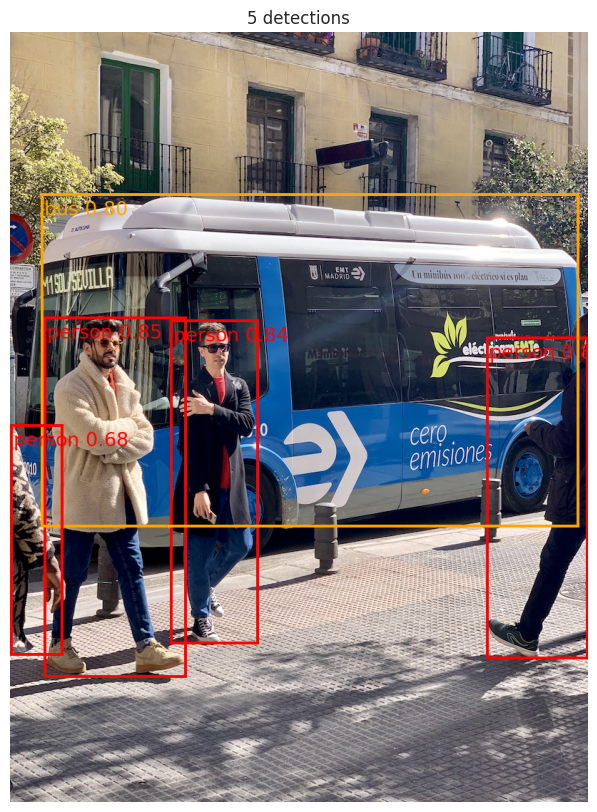

In [38]:
FONT = font_manager.findfont("DejaVu Sans")      # a TrueType font, so the labels are readable
PALETTE = ["red", "yellow", "lime", "cyan", "magenta", "orange", "deepskyblue", "white"]

def draw_detections(image_path, result, ax=None, title=None):
    img = read_image(image_path)                                   # uint8 tensor (3, H, W)
    cls = result.boxes.cls.cpu().int().tolist()
    conf = result.boxes.conf.cpu().tolist()
    labels = [f"{result.names[c]} {p:.2f}" for c, p in zip(cls, conf)]
    colors = [PALETTE[c % len(PALETTE)] for c in cls]              # same class -> same colour

    drawn = draw_bounding_boxes(img, result.boxes.xyxy.cpu(), labels=labels, colors=colors,
                                width=4, font=FONT, font_size=max(12, img.shape[1] // 40))
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 10))
    ax.imshow(drawn.permute(1, 2, 0))                              # (C, H, W) -> (H, W, C)
    ax.set_title(title or f"{len(cls)} detections")
    ax.axis("off")

draw_detections("bus.jpg", res[0])
plt.show()

## YOLO can detect 80 classes out of the box

In [39]:
res[0].names

{0: 'person',
 1: 'bicycle',
 2: 'car',
 3: 'motorcycle',
 4: 'airplane',
 5: 'bus',
 6: 'train',
 7: 'truck',
 8: 'boat',
 9: 'traffic light',
 10: 'fire hydrant',
 11: 'stop sign',
 12: 'parking meter',
 13: 'bench',
 14: 'bird',
 15: 'cat',
 16: 'dog',
 17: 'horse',
 18: 'sheep',
 19: 'cow',
 20: 'elephant',
 21: 'bear',
 22: 'zebra',
 23: 'giraffe',
 24: 'backpack',
 25: 'umbrella',
 26: 'handbag',
 27: 'tie',
 28: 'suitcase',
 29: 'frisbee',
 30: 'skis',
 31: 'snowboard',
 32: 'sports ball',
 33: 'kite',
 34: 'baseball bat',
 35: 'baseball glove',
 36: 'skateboard',
 37: 'surfboard',
 38: 'tennis racket',
 39: 'bottle',
 40: 'wine glass',
 41: 'cup',
 42: 'fork',
 43: 'knife',
 44: 'spoon',
 45: 'bowl',
 46: 'banana',
 47: 'apple',
 48: 'sandwich',
 49: 'orange',
 50: 'broccoli',
 51: 'carrot',
 52: 'hot dog',
 53: 'pizza',
 54: 'donut',
 55: 'cake',
 56: 'chair',
 57: 'couch',
 58: 'potted plant',
 59: 'bed',
 60: 'dining table',
 61: 'toilet',
 62: 'tv',
 63: 'laptop',
 64: 'mou

## 💡 You can limit the classes that are detected with the `classes` parameter
* Let's say that we want to detect only the *bus* object.
    * We need to set `classes` to `[5]`, as this is the ID of *bus*.

In [40]:
# classes=[5] -> detect ONLY buses (ID 5 in COCO); all other classes are ignored
res = yolo("bus.jpg", save_txt=True, save_conf=True, save=True, imgsz=1088, project="yolo", classes=[5])


image 1/1 /content/bus.jpg: 1088x832 1 bus, 15.5ms
Speed: 5.3ms preprocess, 15.5ms inference, 64.4ms postprocess per image at shape (1, 3, 1088, 832)
Results saved to /content/runs/detect/yolo/predict
1 label saved to /content/runs/detect/yolo/predict/labels


## Now only the *bus* was detected

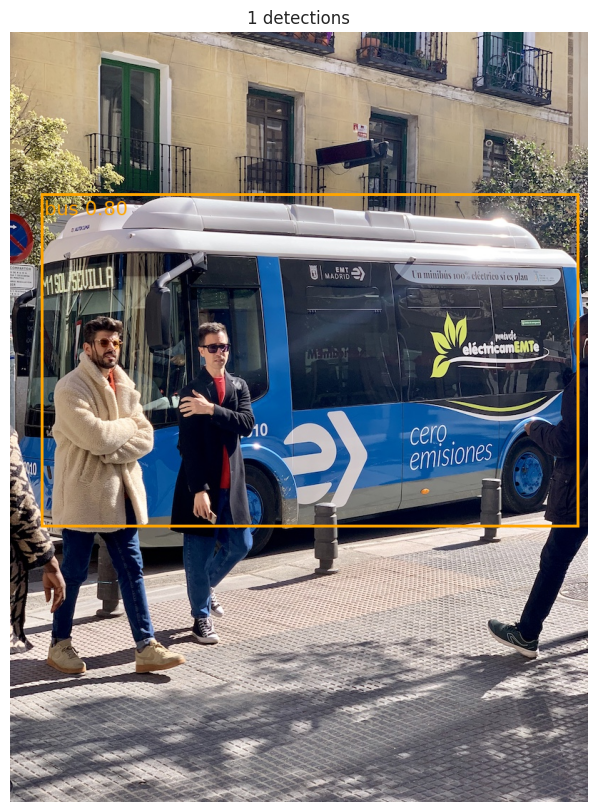

In [41]:
draw_detections("bus.jpg", res[0])
plt.show()

## ✂️ Why one box per object? Non-Maximum Suppression (NMS)

A detector looks at the image in many places at once, so **several candidate boxes** usually
land on the same object. We want to keep only **the best one**. The classic algorithm is
**Non-Maximum Suppression**:

1. Sort all boxes by their **confidence score**.
2. Take the box with the **highest score** and **keep** it.
3. **Remove** every other box that overlaps it with **IoU > threshold** (e.g. 0.5) — they describe the same object.
4. Repeat with the remaining boxes until none are left.

PyTorch has it ready as `torchvision.ops.nms`. Let's try it on four hand-made boxes:
three on the same object and one on a different object.

Indices of the boxes we keep: [0, 3]


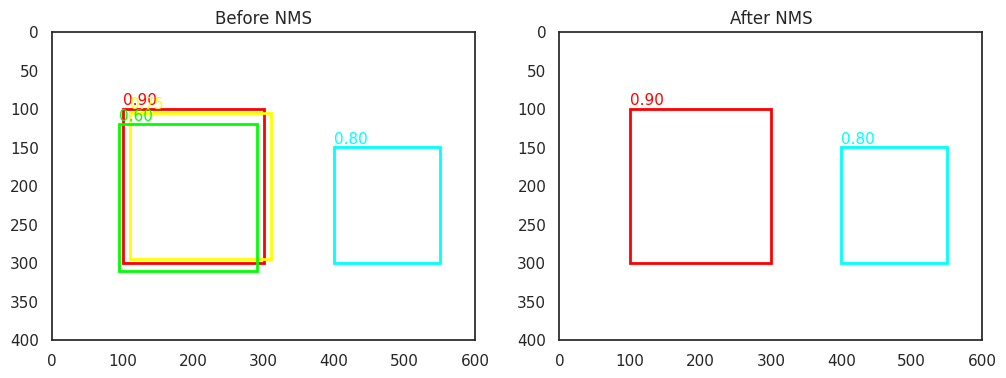

In [42]:
candidate_boxes = torch.tensor([
    [100., 100., 300., 300.],   # object 1 - best guess
    [110., 105., 310., 295.],   # object 1 - almost the same box
    [ 95., 120., 290., 310.],   # object 1 - another duplicate
    [400., 150., 550., 300.],   # object 2 - a different object
])
scores = torch.tensor([0.90, 0.75, 0.60, 0.80])

keep = nms(candidate_boxes, scores, iou_threshold=0.5)
print("Indices of the boxes we keep:", keep.tolist())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, idx, title in [(ax[0], range(len(scores)), "Before NMS"), (ax[1], keep.tolist(), "After NMS")]:
    for i in idx:
        x1, y1, x2, y2 = candidate_boxes[i].tolist()
        a.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, linewidth=2, edgecolor=PALETTE[i]))
        a.text(x1, y1 - 5, f"{scores[i]:.2f}", color=PALETTE[i], fontsize=11)

    a.set_xlim(0, 600)
    a.set_ylim(400, 0)
    a.set_title(title)
plt.show()

* Older YOLO versions run NMS as a separate step **after** the network.
* **YOLO26 is NMS-free**: it was trained to output **a single box per object** directly. Fewer steps → simpler
  and faster deployment, especially on small devices. Most other detectors (including the torchvision ones)
  still rely on NMS, so it is worth knowing.

## YOLO is able to process video files using the same API — let's try it with the downloaded video
* We want to detect the **boats** in the video sequence.
    * 💡 The ID of the *boat* class is `8`.
* 📌 Set `stream=True` so the inference results won't accumulate in RAM and cause an out-of-memory error.

In [43]:
# stream=True -> results are produced lazily, one frame at a time (a Python generator)
# classes=[8] -> detect only boats
res = yolo("video_cut.mkv", stream=True, save_txt=True, save_conf=True, save=True, imgsz=1088,
           project="yolo", classes=[8])

## ⚡ With `stream=True`, the detection is done when we iterate over the `res` object

In [44]:
output = []
start = time.time()
for i, result in enumerate(res):                    # the inference actually runs HERE, frame by frame
    curr = result.boxes.xyxy.cpu().numpy()          # boxes in the current frame
    output.append({
        "Cls": result.boxes.cls.cpu().numpy(),      # class IDs of the detected objects
        "BBoxes": curr,                             # their bounding boxes (xyxy)
    })
elapsed = time.time() - start
print(f"Processed {len(output)} frames in {elapsed:.1f} s ({len(output) / elapsed:.1f} frames per second)")


video 1/1 (frame 1/73) /content/video_cut.mkv: 640x1088 (no detections), 35.2ms
video 1/1 (frame 2/73) /content/video_cut.mkv: 640x1088 (no detections), 11.5ms
video 1/1 (frame 3/73) /content/video_cut.mkv: 640x1088 (no detections), 11.1ms
video 1/1 (frame 4/73) /content/video_cut.mkv: 640x1088 (no detections), 11.2ms
video 1/1 (frame 5/73) /content/video_cut.mkv: 640x1088 (no detections), 11.4ms
video 1/1 (frame 6/73) /content/video_cut.mkv: 640x1088 (no detections), 12.0ms
video 1/1 (frame 7/73) /content/video_cut.mkv: 640x1088 (no detections), 11.8ms
video 1/1 (frame 8/73) /content/video_cut.mkv: 640x1088 (no detections), 11.7ms
video 1/1 (frame 9/73) /content/video_cut.mkv: 640x1088 (no detections), 11.1ms
video 1/1 (frame 10/73) /content/video_cut.mkv: 640x1088 (no detections), 17.0ms
video 1/1 (frame 11/73) /content/video_cut.mkv: 640x1088 (no detections), 11.8ms
video 1/1 (frame 12/73) /content/video_cut.mkv: 640x1088 1 boat, 15.1ms
video 1/1 (frame 13/73) /content/video_cut.mk

## 📊 The bounding boxes are stored in the output list
* 💡 The annotated video is saved in the `yolo/` folder — download it and have a look!

In [45]:
output[8:15]

[{'Cls': array([], dtype=float32),
  'BBoxes': array([], shape=(0, 4), dtype=float32)},
 {'Cls': array([], dtype=float32),
  'BBoxes': array([], shape=(0, 4), dtype=float32)},
 {'Cls': array([], dtype=float32),
  'BBoxes': array([], shape=(0, 4), dtype=float32)},
 {'Cls': array([          8], dtype=float32),
  'BBoxes': array([[     0.3359,      578.24,        63.2,      699.69]], dtype=float32)},
 {'Cls': array([          8], dtype=float32),
  'BBoxes': array([[     0.8535,      573.55,      157.59,      767.36]], dtype=float32)},
 {'Cls': array([          8], dtype=float32),
  'BBoxes': array([[    0.56518,      566.86,      264.72,      807.27]], dtype=float32)},
 {'Cls': array([          8], dtype=float32),
  'BBoxes': array([[          0,      457.64,      391.01,       832.1]], dtype=float32)}]

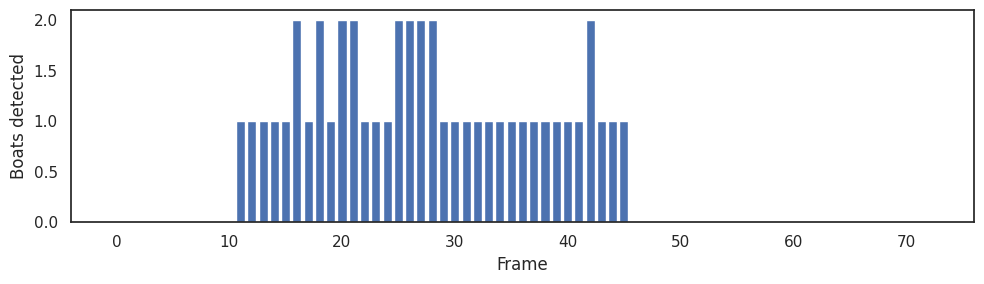

In [46]:
# How many boats did we see in each frame?
boats_per_frame = [len(o["Cls"]) for o in output]
plt.figure(figsize=(10, 3))
plt.bar(range(len(boats_per_frame)), boats_per_frame)
plt.xlabel("Frame"); plt.ylabel("Boats detected")
plt.tight_layout(); plt.show()

# 🚀 We can fine-tune the model using our own data
* It requires a dataset in the **YOLO format**:
    * a folder with **images** and a folder with **labels** — one `.txt` file per image,
    * every line of a label file = one object: `class cx cy w h` — the **normalized `cxcywh`** format from the beginning of the lesson 📦
* And also a **configuration file** (`.yaml`) that says where the data is and what the class names are.

## Let's download the data first

In [47]:
!wget https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/releases/download/v0.0.01/yolo_data.zip -O yolo_data_dir.zip
!unzip -q yolo_data_dir.zip

--2026-11-15 10:06:15--  https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/releases/download/v0.0.01/yolo_data.zip
Resolving github.com (github.com)... 140.82.121.3
Connecting to github.com (github.com)|140.82.121.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/607589422/7d496b62-8936-409e-9949-2c8fe17d2db4?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-11-15T10%3A47%3A00Z&rscd=attachment%3B+filename%3Dyolo_data.zip&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-11-15T09%3A46%3A20Z&ske=2026-11-15T10%3A47%3A00Z&sks=b&skv=2018-11-09&sig=etkUcjuVoyl6QYZ3y1oAfBjsZLOyOSASbU%2FFGZtWQBU%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5NDc0MDc3NSwibmJmIjoxNzk0NzM3MTc1LCJwYXRoIjoicmVsZWFzZWFzc2V0

### 🔍 What does one training example look like?
Let's read one label file and draw its boxes — a nice test that we understand the `cxcywh` format.

Label file content:
8 0.9661458333333334 0.4537037037037037 0.13229166666666667 0.3351851851851852



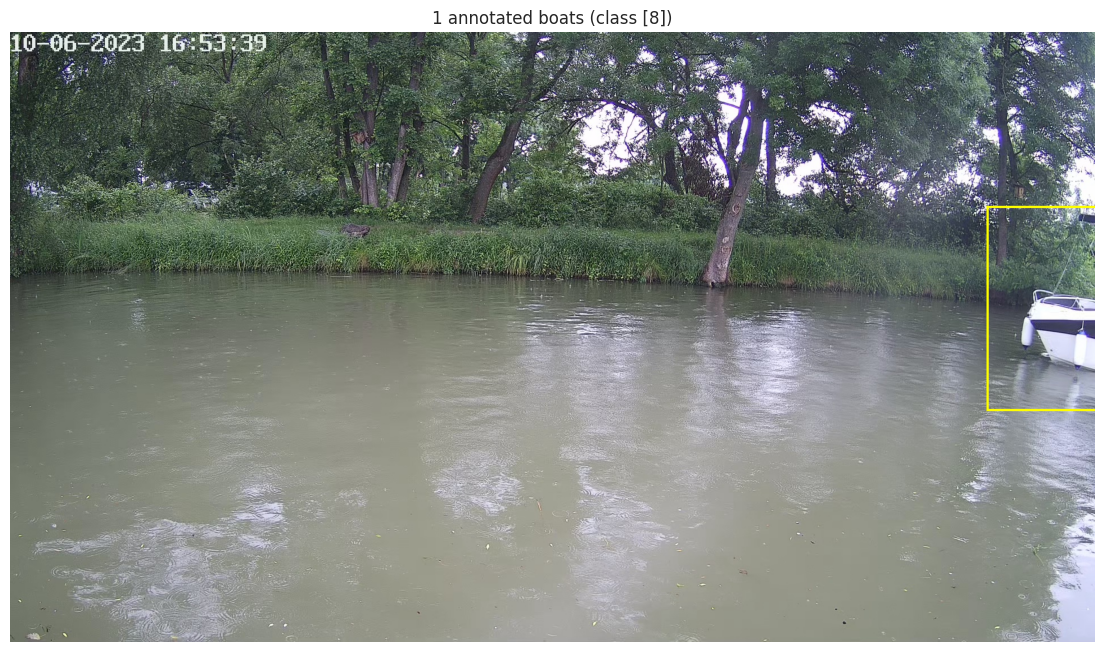

In [48]:
import os, glob

img_path = sorted(glob.glob("yolo_data/images/train/*.jpg"))[0]
label_path = img_path.replace("/images/", "/labels/").replace(".jpg", ".txt")

print("Label file content:")
print(open(label_path).read())

img = read_image(img_path)                                   # (3, H, W)
H, W = img.shape[1:]

label = torch.tensor(np.loadtxt(label_path, ndmin=2), dtype=torch.float32)
cls_ids, boxes_cxcywh = label[:, 0].int(), label[:, 1:]

# normalized cxcywh  ->  pixel xyxy
boxes_xyxy = box_convert(boxes_cxcywh, in_fmt="cxcywh", out_fmt="xyxy") * torch.tensor([W, H, W, H])

drawn = draw_bounding_boxes(img, boxes_xyxy, colors="yellow", width=4)
plt.figure(figsize=(14, 8))
plt.imshow(drawn.permute(1, 2, 0)); plt.axis("off")
plt.title(f"{len(cls_ids)} annotated boats (class {cls_ids.unique().tolist()})")
plt.show()

## Don't forget to download the config file
* 💡 We need to modify the `path` property in the config file so that it points to our data folder.
  The cell below does it for us, so it works in Colab and on your own computer alike.

In [49]:
!wget https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/raw/main/misc/coco128.yaml -O coco128.yaml

--2026-11-15 10:06:27--  https://github.com/rasvob/VSB-FEI-Deep-Learning-Exercises/raw/main/misc/coco128.yaml
Resolving github.com (github.com)... 140.82.121.3
Connecting to github.com (github.com)|140.82.121.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/rasvob/VSB-FEI-Deep-Learning-Exercises/main/misc/coco128.yaml [following]
--2026-11-15 10:06:27--  https://raw.githubusercontent.com/rasvob/VSB-FEI-Deep-Learning-Exercises/main/misc/coco128.yaml
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1425 (1.4K) [text/plain]
Saving to: ‘coco128.yaml’

coco128.yaml        100%[===================>]   1.39K  --.-KB/s    in 0s      

2026-11-15 10:06:27 (32.0 MB/s) - ‘coco128.yaml’ saved [1425/1425]



In [50]:
import yaml

with open("coco128.yaml") as f:
    cfg = yaml.safe_load(f)

cfg["path"] = os.path.abspath("yolo_data")

with open("coco128.yaml", "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

print("path :", cfg["path"])
print("train:", cfg["train"], "| val:", cfg["val"])
print("number of classes:", len(cfg["names"]))

path : /content/yolo_data
train: images/train | val: images/val
number of classes: 80


In [51]:
# Start from the pretrained weights and continue training on our data
ft_model = YOLO("yolo26n.pt")

ft_model.train(data="coco128.yaml", epochs=5, imgsz=1920, batch=8, pretrained=True,
               cache=True, workers=16, seed=13)

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco128.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1920, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=au

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([8])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79c7e04727b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [52]:
# Where were the best weights saved? (usually runs/detect/train/weights/best.pt)
best_path = ft_model.trainer.best
print(best_path)

/content/runs/detect/train/weights/best.pt


## After training the model, we usually want to export it
* You can check the export documentation [here](https://docs.ultralytics.com/modes/export/#export-formats).
* Often the **ONNX** (for CPU) or **TensorRT** (for GPU) export format is used.
    * 💡 **ONNX** = *Open Neural Network Exchange* — a universal file format; the exported model can run
      without PyTorch, e.g. in C++, C#, Java or directly in a web browser.
* The `quantize` parameter reduces the **numeric precision** of the weights:
    * `quantize=16` → **FP16** (half precision): about half the model size, potentially faster inference on supported hardware,
    * `quantize=8` → **INT8**: even smaller, but it needs calibration data (`data=...`),
    * 💡 older Ultralytics versions used `half=True` for FP16 — you will still see it in many tutorials.
* The `simplify` parameter simplifies the model graph for ONNX exports, potentially improving performance and compatibility.

In [53]:
# Export the fine-tuned model to ONNX
#   format="onnx"  - export format (alternatives: "engine" = TensorRT, "tflite", "coreml", ...)
#   imgsz=1920     - must match the resolution used for training
#   quantize=16    - FP16 (half precision): about half the size, faster on supported hardware
#   simplify=True  - simplified ONNX graph
best_model = YOLO(best_path)
onnx_path = best_model.export(format="onnx", imgsz=1920, quantize=16, simplify=True)
print(onnx_path)

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 58.2 GFLOPs

PyTorch: starting from '/content/runs/detect/train/weights/best.pt' with input shape (1, 3, 1920, 1920) BCHW and output shape(s) (1, 84, 75600) (5.5 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 270ms
Prepared 4 packages in 330ms
Installed 4 packages in 28ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.32.0
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimmin

## 🚀 Finally, we can load the model as usual and use it in inference mode
* 💡 We use the path returned by `export()`. If you load the model in a new session, set the path according to your workspace (usually `runs/detect/train/weights/best.onnx`).

In [54]:
onnx_model = YOLO(onnx_path, task="detect", verbose=True)

In [55]:
res = onnx_model("video_cut.mkv", stream=True, save_txt=True, save_conf=True, save=True, imgsz=1920,
                 project="yolo", classes=[8])

Loading /content/runs/detect/train/weights/best.onnx for ONNX Runtime inference...
requirements: Ultralytics requirement ['onnxruntime-gpu[cuda]'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 221ms
Prepared 1 package in 1.91s
Installed 1 package in 54ms
 + onnxruntime-gpu==1.32.0

requirements: AutoUpdate success ✅ 2.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Using ONNX Runtime 1.32.0 with CPUExecutionProvider
WARNING ⚠️ CUDA requested but CUDAExecutionProvider not available. Using CPU...


In [56]:
output_ft = []
start = time.time()
for i, result in enumerate(res):
    curr = result.boxes.xyxy.cpu().numpy()
    output_ft.append({
        "Cls": result.boxes.cls.cpu().numpy(),
        "BBoxes": curr,
    })
elapsed = time.time() - start
print(f"Processed {len(output_ft)} frames in {elapsed:.1f} s ({len(output_ft) / elapsed:.1f} frames per second)")


video 1/1 (frame 1/73) /content/video_cut.mkv: 1920x1920 (no detections), 296.9ms
video 1/1 (frame 2/73) /content/video_cut.mkv: 1920x1920 (no detections), 293.6ms
video 1/1 (frame 3/73) /content/video_cut.mkv: 1920x1920 (no detections), 213.1ms
video 1/1 (frame 4/73) /content/video_cut.mkv: 1920x1920 (no detections), 229.3ms
video 1/1 (frame 5/73) /content/video_cut.mkv: 1920x1920 (no detections), 219.8ms
video 1/1 (frame 6/73) /content/video_cut.mkv: 1920x1920 (no detections), 243.8ms
video 1/1 (frame 7/73) /content/video_cut.mkv: 1920x1920 (no detections), 215.1ms
video 1/1 (frame 8/73) /content/video_cut.mkv: 1920x1920 (no detections), 239.0ms
video 1/1 (frame 9/73) /content/video_cut.mkv: 1920x1920 (no detections), 238.2ms
video 1/1 (frame 10/73) /content/video_cut.mkv: 1920x1920 (no detections), 217.5ms
video 1/1 (frame 11/73) /content/video_cut.mkv: 1920x1920 (no detections), 238.1ms
video 1/1 (frame 12/73) /content/video_cut.mkv: 1920x1920 (no detections), 224.7ms
video 1/1 (f

In [57]:
output_ft[8:15]

[{'Cls': array([], dtype=float32),
  'BBoxes': array([], shape=(0, 4), dtype=float32)},
 {'Cls': array([], dtype=float32),
  'BBoxes': array([], shape=(0, 4), dtype=float32)},
 {'Cls': array([], dtype=float32),
  'BBoxes': array([], shape=(0, 4), dtype=float32)},
 {'Cls': array([], dtype=float32),
  'BBoxes': array([], shape=(0, 4), dtype=float32)},
 {'Cls': array([          8], dtype=float32),
  'BBoxes': array([[     3.3125,      573.25,      158.31,      776.75]], dtype=float32)},
 {'Cls': array([          8], dtype=float32),
  'BBoxes': array([[        1.5,      563.75,       260.5,      828.25]], dtype=float32)},
 {'Cls': array([          8], dtype=float32),
  'BBoxes': array([[          0,      439.75,       394.5,      844.25]], dtype=float32)}]

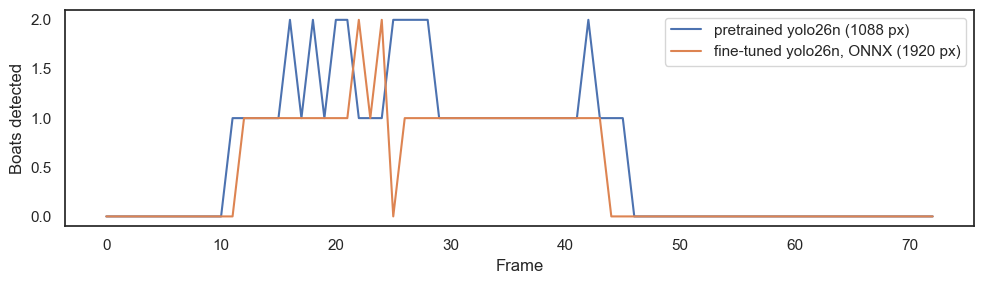

In [58]:
plt.figure(figsize=(10, 3))
plt.plot([len(o["Cls"]) for o in output], label="pretrained yolo26n (1088 px)")
plt.plot([len(o["Cls"]) for o in output_ft], label="fine-tuned yolo26n, ONNX (1920 px)")
plt.xlabel("Frame"); plt.ylabel("Boats detected"); plt.legend()
plt.tight_layout(); plt.show()

# Activities ✏️

Now it is your turn! The code cells below are **empty** — write the code yourself.

Everything you need is already defined in this notebook (`make_dataset`, `build_model`, `predict`,
`plot_pred`, `draw_detections`, …).

## 🧰 Helper for the Part A activities

`train_and_evaluate()` does everything from Part A in one call: it **splits** the data, trains a
**fresh** model and returns the trained model and a dictionary of results.

In [59]:
def train_and_evaluate(X, labels, model=None, loss_fn=None, n_epochs=40, lr=1e-3,
                       batch_size=32, verbose=True):
    """Split the data, train a model and return (trained_model, results_dict)."""
    torch.manual_seed(SEED)
    if model is None:
        model = build_model(n_outputs=labels.shape[1])
    model = model.to(device)
    if loss_fn is None:
        loss_fn = nn.SmoothL1Loss(beta=0.05)

    # the same split as in Part A
    X_tmp, X_te, y_tmp, y_te = train_test_split(X, labels, test_size=0.2, random_state=SEED)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.2, random_state=SEED)
    loader = DataLoader(TensorDataset(torch.tensor(X_tr), torch.tensor(y_tr)),
                        batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    best_iou, best_state, val_history = -1.0, None, []
    start = time.time()
    for epoch in range(n_epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        val_iou = evaluate_iou(model, X_va, y_va)
        val_history.append(val_iou)
        if val_iou > best_iou:
            best_iou, best_state = val_iou, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    results = {
        "val_iou": best_iou,
        "test_iou": evaluate_iou(model, X_te, y_te),
        "n_params": sum(p.numel() for p in model.parameters()),
        "train_time_s": time.time() - start,
        "val_history": val_history,
    }
    if verbose:
        print(f"test IoU = {results['test_iou']:.3f} | val IoU = {best_iou:.3f} | "
              f"{results['train_time_s']:.1f} s")
    return model, results

## Activity 1 — Loss function face-off ⚖️

We used **Smooth L1**. Would another loss give better boxes? Train the model with each loss below
and compare the **test IoU**.

| Loss | Formula (per coordinate, $d$ = error) | Idea |
|---|---|---|
| `nn.MSELoss()` | $d^2$ | punishes big errors a lot |
| `nn.L1Loss()` | $\lvert d \rvert$ | all errors count linearly |
| `nn.SmoothL1Loss(beta=0.05)` | MSE for small $d$, L1 for big $d$ | the best of both |
| `nn.BCELoss()` | $-[y \log p + (1-y)\log(1-p)]$ | treats coordinates as "probabilities" |

🔎 Which loss wins? Is the difference big? Which one learns the **fastest**?


## Activity 2 — Beyond squares 🟦

Real objects are rarely square. Let's switch from circles to **ellipses** — now every box has a
**different width and height**.

**Your task**
1. Generate a dataset of ellipses and check the **shape of the labels**. What does each column mean now?
2. Show a few images with their ground-truth boxes.
3. Build a model with the **correct output layer** and train it.
4. Generate 6 **new** ellipses the model has never seen and plot the predictions (green = truth, red = prediction).

🔎 Is the IoU better or worse than for circles? Why?


## Activity 3 — Beat the baseline 🏆

Remember the **test IoU** of our model from Part A? Your goal: **beat it**.

**What you may change:**
* number of filters in the convolutional layers,
* dropout — keep it, lower it, remove it,
* add **batch normalization**,
* learning rate, number of epochs, amount of training data.


## Activity 4 — The confidence threshold 🎚️

Every YOLO detection comes with a **confidence** score. Only boxes above the threshold `conf`
(default `0.25`) are returned.

**Your task**
1. Run YOLO on `bus.jpg` with `conf` = 0.05, 0.25, 0.5 and 0.8.
2. Count the detections and show the four results **side by side**.

🔎 Questions
* What kind of mistakes appear with a **very low** threshold? And with a **very high** one?
* You are building a **pedestrian warning system** for a car 🚗. Low or high threshold?
  And for an app that automatically **tags your holiday photos** 🏖️?
